In [1]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.utils.class_weight import compute_class_weight

In [2]:

# PATHS

ROOT_DIR = Path(r"C:\Btech\SEM5\cuda\DL\Frames_854_Stratified")

TRAIN_DIR = ROOT_DIR / "Training"
VAL_DIR   = ROOT_DIR / "Validation"
TEST_DIR  = ROOT_DIR / "Testing"


# CLASSES


CLASSES = [
    "Distraction",
    "Drinking",
    "Normal",
    "Phone",
    "Sleeping"
]

CLASS_TO_IDX = {
    name: idx
    for idx, name in enumerate(CLASSES)
}

# TRAINING SETTINGS


SEED = 42

BATCH_SIZE = 16          
NUM_WORKERS = 0

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}


# REPRODUCIBILITY


random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


print("Device :", DEVICE)

if torch.cuda.is_available():
    print("GPU    :", torch.cuda.get_device_name(0))



Device : cuda
GPU    : NVIDIA GeForce RTX 4060 Laptop GPU


In [5]:
def build_dataframe(split_path):

    data = []

    for class_name in CLASSES:

        class_folder = split_path / class_name

        if not class_folder.exists():
            continue

        for image_path in class_folder.iterdir():

            if image_path.suffix.lower() in IMAGE_EXTENSIONS:

                data.append({
                    "path": str(image_path),
                    "class": class_name,
                    "label": CLASS_TO_IDX[class_name]
                })

    return pd.DataFrame(data)


train_df = build_dataframe(TRAIN_DIR)
val_df   = build_dataframe(VAL_DIR)
test_df  = build_dataframe(TEST_DIR)

print("Training Images  :", len(train_df))
print("Validation Images:", len(val_df))
print("Testing Images   :", len(test_df))

Training Images  : 23026
Validation Images: 4935
Testing Images   : 4936


In [6]:
print("TRAINING")
display(train_df["class"].value_counts().sort_index())

print("\nVALIDATION")
display(val_df["class"].value_counts().sort_index())

print("\nTESTING")
display(test_df["class"].value_counts().sort_index())

TRAINING


class
Distraction    4370
Drinking       4913
Normal         4365
Phone          4937
Sleeping       4441
Name: count, dtype: int64


VALIDATION


class
Distraction     936
Drinking       1053
Normal          936
Phone          1058
Sleeping        952
Name: count, dtype: int64


TESTING


class
Distraction     937
Drinking       1053
Normal          936
Phone          1058
Sleeping        952
Name: count, dtype: int64

In [7]:
# IMAGE TRANSFORMS

train_transform = transforms.Compose([

    # Geometric Augmentation 
    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomRotation(degrees=8),

    transforms.RandomAffine(
        degrees=0,
        translate=(0.03, 0.03),   # slight seat shift
        scale=(0.95, 1.05)
    ),

    #Lighting Augmentation
    transforms.ColorJitter(
        brightness=0.20,
        contrast=0.20,
        saturation=0.15,
        hue=0.03
    ),

    # Slight blur to reduce identity memorization
    transforms.RandomApply([
        transforms.GaussianBlur(kernel_size=3)
    ], p=0.20),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# Validation & Test
# No augmentation — only normalization

test_transform = transforms.Compose([

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [8]:
class DriverDataset(Dataset):

    def __init__(self, dataframe, transform):

        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):

        row = self.df.iloc[index]

        image = Image.open(row["path"]).convert("RGB")

        image = self.transform(image)

        label = row["label"]

        return image, label


train_dataset = DriverDataset(train_df, train_transform)
val_dataset   = DriverDataset(val_df, test_transform)
test_dataset  = DriverDataset(test_df, test_transform)

In [9]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)


# Class Weights (for imbalance)


weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(CLASSES)),
    y=train_df["label"]
)

class_weights = torch.tensor(
    weights,
    dtype=torch.float32
).to(DEVICE)

print("Class Weights")
for c, w in zip(CLASSES, weights):
    print(f"{c:15s}: {w:.3f}")

print("\nTrain Batches :", len(train_loader))
print("Val Batches   :", len(val_loader))
print("Test Batches  :", len(test_loader))

Class Weights
Distraction    : 1.054
Drinking       : 0.937
Normal         : 1.055
Phone          : 0.933
Sleeping       : 1.037

Train Batches : 1440
Val Batches   : 309
Test Batches  : 309


In [10]:

# CUSTOM CNN


class CustomCNN(nn.Module):

    def __init__(self, num_classes=5):
        super().__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(3, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(32, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(64, 128, 3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Block 4
            nn.Conv2d(128, 256, 3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Block 5
            nn.Conv2d(256, 512, 3, padding=1, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True),

            nn.AdaptiveAvgPool2d((1,1))
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            # dropout
            nn.Dropout(0.60),

            nn.Linear(512, 256),
            nn.ReLU(inplace=True),

            nn.Dropout(0.40),

            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


# Create model
model = CustomCNN(len(CLASSES)).to(DEVICE)

total_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(model)
print(f"\nTrainable Parameters: {total_params:,}")

CustomCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1

In [11]:
# VERIFY SHAPES


images, labels = next(iter(train_loader))

print("Input Shape :", images.shape)

images = images.to(DEVICE)

outputs = model(images)

print("Output Shape:", outputs.shape)

Input Shape : torch.Size([16, 3, 480, 854])
Output Shape: torch.Size([16, 5])


In [12]:
# TRAINING CONFIGURATION

LEARNING_RATE = 1e-4
EPOCHS = 20


# Loss Function


criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.05
)

# Optimizer


optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)


# Learning Rate Scheduler


scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2,
    threshold=1e-3,
    min_lr=1e-6
)

# Mixed Precision 

scaler = torch.amp.GradScaler("cuda")

# Early Stopping


EARLY_STOPPING_PATIENCE = 8


print("Training Configuration")

print(f"Learning Rate : {LEARNING_RATE}")
print(f"Epochs        : {EPOCHS}")
print(f"Patience      : {EARLY_STOPPING_PATIENCE}")


Training Configuration
Learning Rate : 0.0001
Epochs        : 20
Patience      : 8


In [13]:
from sklearn.metrics import accuracy_score, f1_score
from tqdm import tqdm
import copy

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
    "train_f1": [],
    "val_f1": []
}

best_f1 = 0
trigger = 0

best_model = copy.deepcopy(model.state_dict())

for epoch in range(EPOCHS):

    print(f"\nEpoch [{epoch+1}/{EPOCHS}]")
    print("-"*50)

    model.train()

    train_loss = 0
    train_true = []
    train_pred = []

    for images, labels in tqdm(train_loader):

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda"):

            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        scaler.step(optimizer)
        scaler.update()

        train_loss += loss.item()

        preds = outputs.argmax(dim=1)

        train_true.extend(labels.cpu().numpy())
        train_pred.extend(preds.cpu().numpy())

    train_loss /= len(train_loader)

    train_acc = accuracy_score(train_true, train_pred)
    train_f1 = f1_score(train_true, train_pred, average="macro")

    model.eval()

    val_loss = 0
    val_true = []
    val_pred = []

    with torch.no_grad():

        for images, labels in tqdm(val_loader):

            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

            preds = outputs.argmax(dim=1)

            val_true.extend(labels.cpu().numpy())
            val_pred.extend(preds.cpu().numpy())

    val_loss /= len(val_loader)

    val_acc = accuracy_score(val_true, val_pred)
    val_f1 = f1_score(val_true, val_pred, average="macro")

    scheduler.step(val_f1)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    history["train_f1"].append(train_f1)
    history["val_f1"].append(val_f1)

    if val_f1 > best_f1:

        best_f1 = val_f1
        trigger = 0

        best_model = copy.deepcopy(model.state_dict())
        torch.save(best_model, "best_custom_cnn.pth")

        status = "Best Model Saved"

    else:

        trigger += 1
        status = f"EarlyStop {trigger}/{EARLY_STOPPING_PATIENCE}"

    print(
        f"Train Loss : {train_loss:.4f} | "
        f"Acc : {train_acc:.4f} | "
        f"F1 : {train_f1:.4f}"
    )

    print(
        f"Val Loss   : {val_loss:.4f} | "
        f"Acc : {val_acc:.4f} | "
        f"F1 : {val_f1:.4f}"
    )

    print(status)

    if trigger >= EARLY_STOPPING_PATIENCE:

        print("\nEarly Stopping Triggered")
        break

print("\nTraining Completed")


Epoch [1/20]
--------------------------------------------------


  0%|          | 0/1440 [00:00<?, ?it/s]

100%|██████████| 309/309 [01:11<00:00,  4.31it/s]


Train Loss : 1.5831 | Acc : 0.2553 | F1 : 0.2512
Val Loss   : 1.5633 | Acc : 0.2896 | F1 : 0.2444
Best Model Saved

Epoch [2/20]
--------------------------------------------------


100%|██████████| 309/309 [00:45<00:00,  6.81it/s]


Train Loss : 1.5279 | Acc : 0.3087 | F1 : 0.3015
Val Loss   : 1.5331 | Acc : 0.2871 | F1 : 0.2370
EarlyStop 1/8

Epoch [3/20]
--------------------------------------------------


... (32 outputs left out)

100%|██████████| 309/309 [00:44<00:00,  6.94it/s]


Train Loss : 0.7849 | Acc : 0.7568 | F1 : 0.7563
Val Loss   : 0.7189 | Acc : 0.7980 | F1 : 0.7982
EarlyStop 2/8

Epoch [20/20]
--------------------------------------------------


100%|██████████| 309/309 [00:44<00:00,  6.94it/s]

Train Loss : 0.7634 | Acc : 0.7686 | F1 : 0.7684
Val Loss   : 0.6569 | Acc : 0.8261 | F1 : 0.8247
Best Model Saved

Training Completed


In [14]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# LOAD BEST MODEL


model.load_state_dict(torch.load("best_custom_cnn.pth"))
model.eval()

test_predictions = []
test_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(DEVICE, non_blocking=True)

        outputs = model(images)

        preds = outputs.argmax(dim=1).cpu().numpy()

        test_predictions.extend(preds)
        test_labels.extend(labels.numpy())

print("Best model loaded successfully.")

C:\Users\rakes\AppData\Local\Temp\ipykernel_10964\880792786.py:13: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("best_custom_cnn.pth"))


Best model loaded successfully.


In [15]:
test_accuracy = accuracy_score(test_labels, test_predictions)

test_precision = precision_score(
    test_labels, test_predictions,
    average="macro", zero_division=0
)

test_recall = recall_score(
    test_labels, test_predictions,
    average="macro", zero_division=0
)

test_f1 = f1_score(
    test_labels, test_predictions,
    average="macro"
)


print("FINAL TEST RESULTS")


print(f"Accuracy  : {test_accuracy:.4f}")
print(f"Precision : {test_precision:.4f}")
print(f"Recall    : {test_recall:.4f}")
print(f"Macro F1  : {test_f1:.4f}")

print("\nCLASSIFICATION REPORT\n")

print(classification_report(
    test_labels,
    test_predictions,
    target_names=CLASSES,
    digits=4
))

cm = confusion_matrix(test_labels, test_predictions)

FINAL TEST RESULTS
Accuracy  : 0.8274
Precision : 0.8562
Recall    : 0.8239
Macro F1  : 0.8269

CLASSIFICATION REPORT

              precision    recall  f1-score   support

 Distraction     0.9819    0.6361    0.7720       937
    Drinking     0.7116    0.9582    0.8167      1053
      Normal     0.9487    0.8301    0.8855       936
       Phone     0.9055    0.8336    0.8681      1058
    Sleeping     0.7335    0.8613    0.7923       952

    accuracy                         0.8274      4936
   macro avg     0.8562    0.8239    0.8269      4936
weighted avg     0.8536    0.8274    0.8276      4936



In [16]:
#Create Results Folder

from pathlib import Path

RESULTS_DIR = Path("Training_Results")
RESULTS_DIR.mkdir(exist_ok=True)

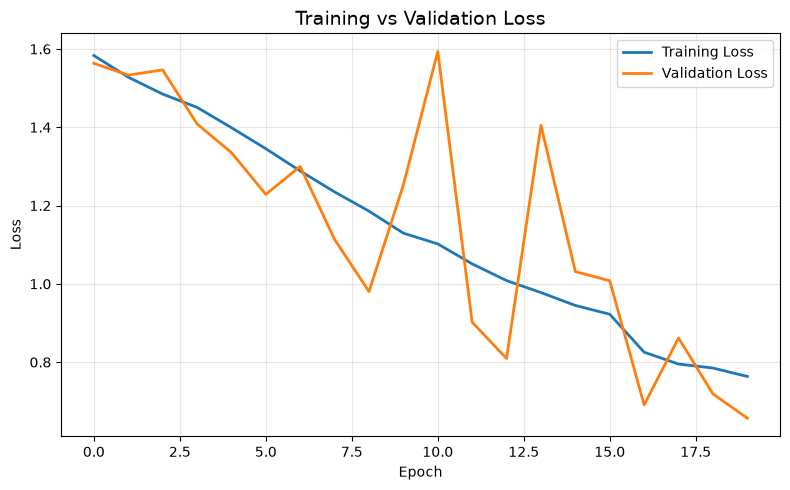

In [17]:
#Loss Curve

plt.figure(figsize=(8,5))

plt.plot(history["train_loss"], linewidth=2, label="Training Loss")
plt.plot(history["val_loss"], linewidth=2, label="Validation Loss")

plt.title("Training vs Validation Loss", fontsize=14)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.savefig(RESULTS_DIR / "loss_curve.png", dpi=300)
plt.show()

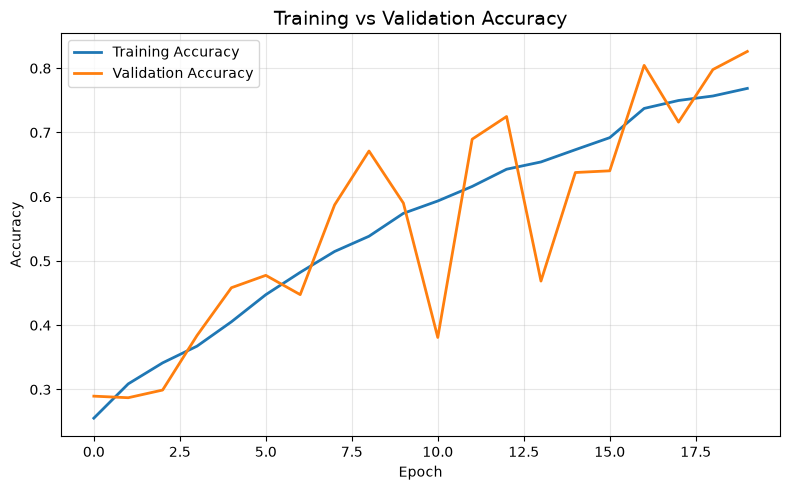

In [18]:
#Accuracy Curve

plt.figure(figsize=(8,5))

plt.plot(history["train_acc"], linewidth=2, label="Training Accuracy")
plt.plot(history["val_acc"], linewidth=2, label="Validation Accuracy")

plt.title("Training vs Validation Accuracy", fontsize=14)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.savefig(RESULTS_DIR / "accuracy_curve.png", dpi=300)
plt.show()

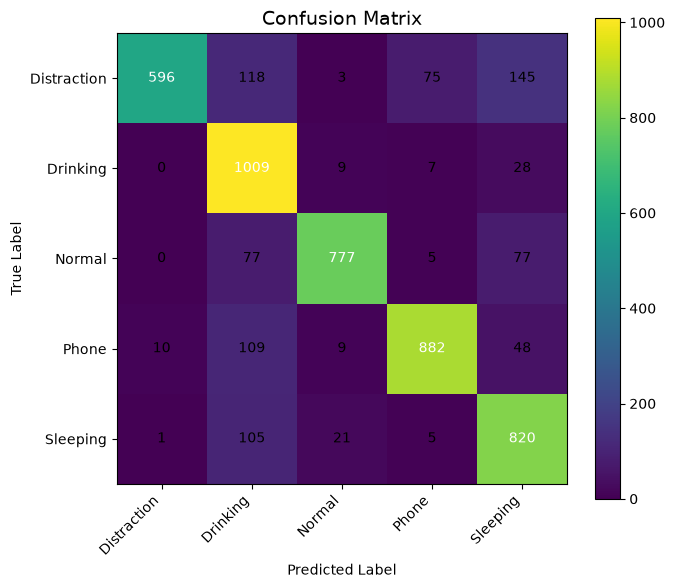

In [19]:
# Confusion Matrix

fig, ax = plt.subplots(figsize=(7,6))

im = ax.imshow(cm, interpolation="nearest")

ax.set_title("Confusion Matrix", fontsize=14)
ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")

ax.set_xticks(np.arange(len(CLASSES)))
ax.set_yticks(np.arange(len(CLASSES)))

ax.set_xticklabels(CLASSES, rotation=45, ha="right")
ax.set_yticklabels(CLASSES)

# Write values inside cells
threshold = cm.max() / 2

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):

        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            color="white" if cm[i, j] > threshold else "black"
        )

fig.colorbar(im)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "confusion_matrix.png", dpi=300)
plt.show()

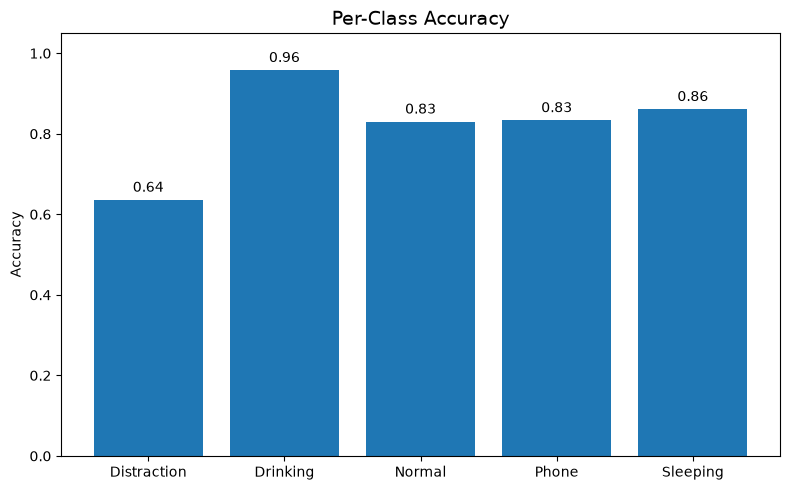

In [20]:
# Per-Class Accuracy
class_accuracy = cm.diagonal() / cm.sum(axis=1)

plt.figure(figsize=(8,5))

plt.bar(CLASSES, class_accuracy)

plt.ylim(0,1.05)

plt.title("Per-Class Accuracy", fontsize=14)
plt.ylabel("Accuracy")

for i, value in enumerate(class_accuracy):

    plt.text(
        i,
        value + 0.02,
        f"{value:.2f}",
        ha="center",
        fontsize=10
    )

plt.tight_layout()
plt.savefig(RESULTS_DIR / "per_class_accuracy.png", dpi=300)
plt.show()

In [21]:
#Train summary

summary = pd.DataFrame({
    "Metric": [
        "Test Accuracy",
        "Precision",
        "Recall",
        "Macro F1"
    ],
    "Value": [
        test_accuracy,
        test_precision,
        test_recall,
        test_f1
    ]
})

display(summary)

summary.to_csv(
    RESULTS_DIR / "test_metrics.csv",
    index=False
)

,Metric,Value
0,Test Accuracy,0.827391
1,Precision,0.856232
2,Recall,0.823882
3,Macro F1,0.826909
